# Computational Linear Algebra: PCA Homework

## Francesco Della Santa, Computational Linear Algebra for Large Scale Problems, Politecnico di Torino

**ATTENTION:** the presentation of this homework to the students happened during the laboratory of 20/11/2026. The recording of that laboratory is available on the web page of the course. *Before asking any question to the teacher*, please read carefully this notebook and view the recorded laboratory of 20/11/2026.

**ATTENTION:** We strongly suggest to view the recorded laboratory of 20/11/2026, since it contains a simulation of this homework.

## Guidelines

**ATTENTION:** the homework evaluation depend also on the level of the homework's compliance with the following guidelines.

### General Guidelines
1. The assignment can be done at most in **teams of 3 people**;
2. **People in the same team are expected to take the exam in the same call, the same day, alltogether**. If a team member fails the exam or rejects the mark he/she can take the exam in another call maintaining the same report.
3. The part of exam related to PCA and $k$-Means will consist in:
   1. A **presentation of 10 minutes** of the homework (*12 minutes for teams of three people*), made *using directly the printed PDF of this notebook*. **No presentations, slides, or similar tools are allowed**.
   2. After the presentation, there will be a discussion with the teacher, asking **questions to the team members related to PCA and $k$-Means**.

    For more details, see the *Discussion Guidelines* below.

4. The final score of this part of exam depends both on the homework contents and the defense; then, **people belonging to the same team can obtain different scores**, according to their defense performance.
5. **python modules not included in the list of the course cannot be used in the homework**, unless you obtain the permission from the teacher.

### Guidelines for Submitting the Homework
1. You are expected to submit, though *"Consegna Elaborati"* on the page of the cours, **a single zip file per group (and not per person)**, containing:
    1. This jupyter notebook of the homework, filled with your codes, comments and results;
    2. The PDF report obtained by printing the notebook. **This PDF will be the one to be used during the presentation**.
2. The **zip file must have the same filename of the notebook, exactly like the PDF**. This name consist in
   $$
   \texttt{HWpca\_Surname1\_Surname2\_Surname3}
   $$
   where the surnames are in **alphabetical order and without whitespaces** (remove surnames for teams with less than 3 members).
4. If you do not submit the homework following these rules, the submission *could be considered not valid*.
5. The deadline for submitting the homework is **the same deadline for registering to the exam**.

### Discussion Guidelines

1. For the discussion of the report, **the team must bring a PC** with the notebook ready to be run, in case of needs, and the **PDF of the report**.
2. The team will have **10 minutes to present** (*12 minutes for teams of three people*) the results contained in the report, **by using the PDF**. After the presentation, there will be a discussion with the teacher, asking **questions to the team members that will involve also the theory behind the methods**.
3. The team members will discuss the report directly commenting on it (i.e., on the PDF file), **without running the code, supporting slides, or other kind of summarizing presentations**.

## The Problem of the Homework

The dataset used in this homework is the *Young-People-Survey* (YPS) dataset; the dataset origin dates back to 2013, when were asked to the **students** of the Statistics class at the Faculty of Social and Economic Sciences of the University of Bratislava to invite their friends to **participate in a survey**. The questions in the survey concern eight different categories of questions:
1. Music preferences (19 items)
2. Movie preferences (12 items)
3. Hobbies & interests (32 items)
4. Phobias (10 items)
5. Health habits (3 items)
6. Personality traits, views on life, & opinions (57 items)
7. Spending habits (7 items)
8. Demographics (10 items)

**N.B.:** Excluding the "*Demographics*" group, almost all the answers consist of a rating between 1 and 5. The non-rating answers are instead characterized by *categorical values; however, these values can be considered ordered*...


Moreover, we can identify *three types of questions* that group "similar" categories:
1. Entertainment questions: music preferences, movie preferences, hobby & interests (63 items);
2. Personality questions: phobias, health habits, personality traits (etc.), spending habits (77 items);
3. Demographics questions: demographics (10 items).

### The Files

Inside the homework’s folder, excluding the notebook, you can find two files:
- *responses_hw.csv*: the data file with all the responses of the people to the survey (each row is a person, each column is a question);
- *columns_hw.csv*: a file that show the original question in the survey and the column name in responses hw.csv.

Some characteristics to be known concerning the dataset are:
- The data file responses_hw.csv consists of 674 rows and 150 columns (139 integer and 11 categorical).
- The dataset is **already cleansed**.


### The Problem - Simulating a Real World Case Scenario

Given the YPS dataset, you must use the *Principal Component Analysis* (PCA) to reduce the dimensionality of the problem and, then, identify meaningful clusters of people (if existing) using the $k$-Means algorithm. Detailed instructions for the exercises are written at the beginning of each exercise.

With this homework we want to *simulate an hypothetical situation where a company wants to identify meaningful profiles of their customers*. Typically, all the information gathered with a customer survey must be summarized with few and easily-comprehensible concepts to help the managers with future decisions. Then, in these situations, very often the number $m$ of chosen *Principal Components* (PCs) is very low, giving more importance to the dimensionality reduction than the preservation of the information.


## Exercise 0.0: Initialization
Fill the missing values in this text box. **Remove the information of other students if you are less than three members**.

**Academic Year:** YYYY/YYYY

### Team Members (Alphabetical Order):
1. Surname1, Name1 (StudentID1);
2. Surname2, Name2 (StudentID2).
3. Surname3, Name3 (StudentID3).

Now, fill the python list below with the Student IDs of the team

In [ ]:
StudentIDs = []  # <-------- Fill this list with Student IDs of the team

## Exercise 0.1: Starting Code-Cell 

Download the .csv files from the web page of the course (*responses_hw.csv* and *columns_hw.csv*) and past them in **the same folder of this notebook**.


Then, run the cell below, **without modifing any line of code**.

The output of this code cell is **your personal subset of the original dataset**, with 2/3 of the original features (i.e., columns) and 3/4 of the original persons (i.e., rows).

### ATTENTION: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL, ANY CHANGE CAN INVALIDATE THE HOMEWORK!

In [6]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Finances
Shopping centres
Branded clothing
Spending on looks
Spending on gadgets
Smoking
Healthy eating
History
Psychology
Politics
Mathematics
Biology
Reading
Geography
Medicine
Law
Cars
Art exhibitions
Religion
Dancing
Writing
Celebrities
Shopping
Theatre
Fun with friends
Pets
Movies
Horror
Romantic
Sci-fi
War
Fantasy/Fairy tales
Animated
Documentary
Western
Action
Music
Slow songs or fast songs
Dance
Country
Classical music
Rock
Punk
Hiphop, Rap
Reggae, Ska
Techno, Trance
Opera
Daily events
Prioritising workload
Writing notes
Workaholism
Final judgement
Keeping promises
Loss of interest
Funniness
Fake
Criminal damage
Self-criticism
Empathy
Eating to survive
Giving
Loneliness
Cheating in school
Health
Charity
Punctuality
Lying
New environment
Mood swings
Appearence and gestures
Socializing
Achievements
Responding to a serious letter
Children
Assertiveness
Getting angry
Knowing the right people
Public speaking
Unpopularit

,Finances,Shopping centres,Branded clothing,Spending on looks,Spending on gadgets,Smoking,Healthy eating,History,Psychology,Politics,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
472,3,2,3,2,4,tried smoking,4,5,5,5,...,21,187,73,4,male,right,college/bachelor degree,no,city,house/bungalow
476,4,3,2,3,2,current smoker,3,3,3,1,...,26,168,65,3,female,right,college/bachelor degree,no,village,house/bungalow
121,3,5,4,4,2,tried smoking,3,3,4,5,...,20,168,60,1,female,right,college/bachelor degree,yes,city,block of flats
198,2,5,3,4,4,former smoker,2,5,5,4,...,20,170,70,1,female,right,college/bachelor degree,no,city,block of flats
487,3,4,4,1,5,never smoked,2,4,1,3,...,29,183,111,1,male,left,secondary school,no,village,house/bungalow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
613,1,4,4,4,4,tried smoking,3,2,2,2,...,22,167,50,1,female,right,secondary school,no,city,block of flats
130,5,3,5,3,3,tried smoking,3,5,5,3,...,22,182,75,1,male,right,secondary school,no,city,block of flats
461,3,1,1,1,4,tried smoking,3,5,3,1,...,23,162,65,1,female,right,college/bachelor degree,no,city,block of flats
455,3,3,3,3,3,current smoker,3,3,4,3,...,23,170,60,1,female,right,secondary school,no,city,block of flats



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Finances,Shopping centres,Branded clothing,Spending on looks,Spending on gadgets,Smoking,Healthy eating,History,Psychology,Politics,...,Getting up,Parents' advice,Questionnaires or polls,Internet usage,Storm,Heights,Spiders,Rats,Ageing,Dangerous dogs
472,3,2,3,2,4,tried smoking,4,5,5,5,...,5,3,3,few hours a day,2,1,3,2,1,2
476,4,3,2,3,2,current smoker,3,3,3,1,...,4,3,2,few hours a day,3,3,2,5,3,5
121,3,5,4,4,2,tried smoking,3,3,4,5,...,5,5,1,few hours a day,2,4,4,5,4,4
198,2,5,3,4,4,former smoker,2,5,5,4,...,5,2,3,few hours a day,1,5,4,1,3,2
487,3,4,4,1,5,never smoked,2,4,1,3,...,1,3,4,few hours a day,2,2,2,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
613,1,4,4,4,4,tried smoking,3,2,2,2,...,3,1,1,most of the day,4,4,3,3,3,4
130,5,3,5,3,3,tried smoking,3,5,5,3,...,4,3,4,few hours a day,2,2,5,1,3,5
461,3,1,1,1,4,tried smoking,3,5,3,1,...,1,4,3,few hours a day,1,1,3,3,3,1
455,3,3,3,3,3,current smoker,3,3,4,3,...,3,3,3,few hours a day,1,1,1,1,1,1



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
472,21,187,73,4,male,right,college/bachelor degree,no,city,house/bungalow
476,26,168,65,3,female,right,college/bachelor degree,no,village,house/bungalow
121,20,168,60,1,female,right,college/bachelor degree,yes,city,block of flats
198,20,170,70,1,female,right,college/bachelor degree,no,city,block of flats
487,29,183,111,1,male,left,secondary school,no,village,house/bungalow
...,...,...,...,...,...,...,...,...,...,...
613,22,167,50,1,female,right,secondary school,no,city,block of flats
130,22,182,75,1,male,right,secondary school,no,city,block of flats
461,23,162,65,1,female,right,college/bachelor degree,no,city,block of flats
455,23,170,60,1,female,right,secondary school,no,city,block of flats


## Exercise 0.2: Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.

For reproducibility, **no extra modules are allowed**.

**DO NOT IMPORT NUMPY NOR PANDAS**, they are already imported.

In [22]:
# DO NOT IMPORT NUMPY AND PANDAS - Already imported
#Ex 1
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

#Ex 2
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

#Ex 4
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#Ex 6
from sklearn.metrics import silhouette_score, silhouette_samples


## Exercise 1. Dataset Preprocessing

In this exercise, you have to do the following operations on the dataset of the features **responses_ft**:
1. Create a new dataframe called **responses_ft_enc** by encoding the categorical features (if they exist), motivating your choices;
1. Create a new dataframe called **responses_ft_pp** by preprocessing the data in **responses_ft_enc**, according to the scaler reported in the cell below.

In [ ]:
print(f'*** YOU HAVE TO APPLY A PREPROCESSING USING THE {your_scaler}')

# Identify numerical and categorical columns
str_mask = responses_ft.dtypes.apply(pd.api.types.is_string_dtype)

# Categorical encoding
categorical_preprocessing = Pipeline([
    ("ohe", OneHotEncoder(sparse_output=False)) #output NOT a sparse matrix
])

encoder = ColumnTransformer(
    transformers=[
        ("cat", categorical_preprocessing, responses_ft.columns[str_mask])
    ],
    verbose_feature_names_out=False
)

# Apply encoding and create a DataFrame
responses_ft_enc = pd.DataFrame(
    encoder.fit_transform(responses_ft),
    columns=encoder.get_feature_names_out(),
    index=responses_ft.index
)

# Apply MinMax scaling
scaler = MinMaxScaler() 
#applicare minmaxscaler al risultato di una ohe è generalmente non cambia nulla;

responses_ft_pp = pd.DataFrame(
    scaler.fit_transform(responses_ft_enc),
    columns=responses_ft_enc.columns,
    index=responses_ft_enc.index
)

display(responses_ft_enc)
display(responses_ft_pp)


*** YOU HAVE TO APPLY A PREPROCESSING USING THE MinMaxScaler


,Smoking_current smoker,Smoking_former smoker,Smoking_never smoked,Smoking_tried smoking,Punctuality_early,Punctuality_late,Punctuality_on time,Lying_everytime it suits me,Lying_never,Lying_only to avoid hurting someone,Lying_sometimes,Internet usage_few hours a day,Internet usage_less than an hour a day,Internet usage_most of the day
472,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
476,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
121,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
198,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
487,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
613,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
130,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
461,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
455,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


,Smoking_current smoker,Smoking_former smoker,Smoking_never smoked,Smoking_tried smoking,Punctuality_early,Punctuality_late,Punctuality_on time,Lying_everytime it suits me,Lying_never,Lying_only to avoid hurting someone,Lying_sometimes,Internet usage_few hours a day,Internet usage_less than an hour a day,Internet usage_most of the day
472,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
476,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
121,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
198,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
487,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
613,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
130,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
461,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
455,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


For doing this exercise, fill the cells below following the instructions you read.

#### Describe and motivate the encoding operations you will apply (max 150 words):
...

#### Describe the preprocessing operation you will apply and comment the effects it may have on the data (max 150 words):
...

#### Write the code for performing the encoding and preprocessing operations of the exercise. Show the encoded data and the preprocessed data you obtain, plus any additional table/value that can be useful for commenting the results:

In [ ]:
# [write the code here]

#### Comment the results obtained after the preprocessing operation (max 100 words):
...

## Exercise 2. Analyzing the Variance and the PCs

In this exercise, you have to do the following operations:
1. compute and visualize the variance of all the features in *responses_ft_enc* and *responses_ft_pp*;
1. compute all the $n$ Principal Components (PCs) for *responses_ft_enc* and *responses_ft_pp*, separately, and visualize the curves of the cumulative explained variances.

For doing this exercise, fill the cells below following the instructions you read.

#### Write the code for computing and visualizing the variance of the features of the two datasets:

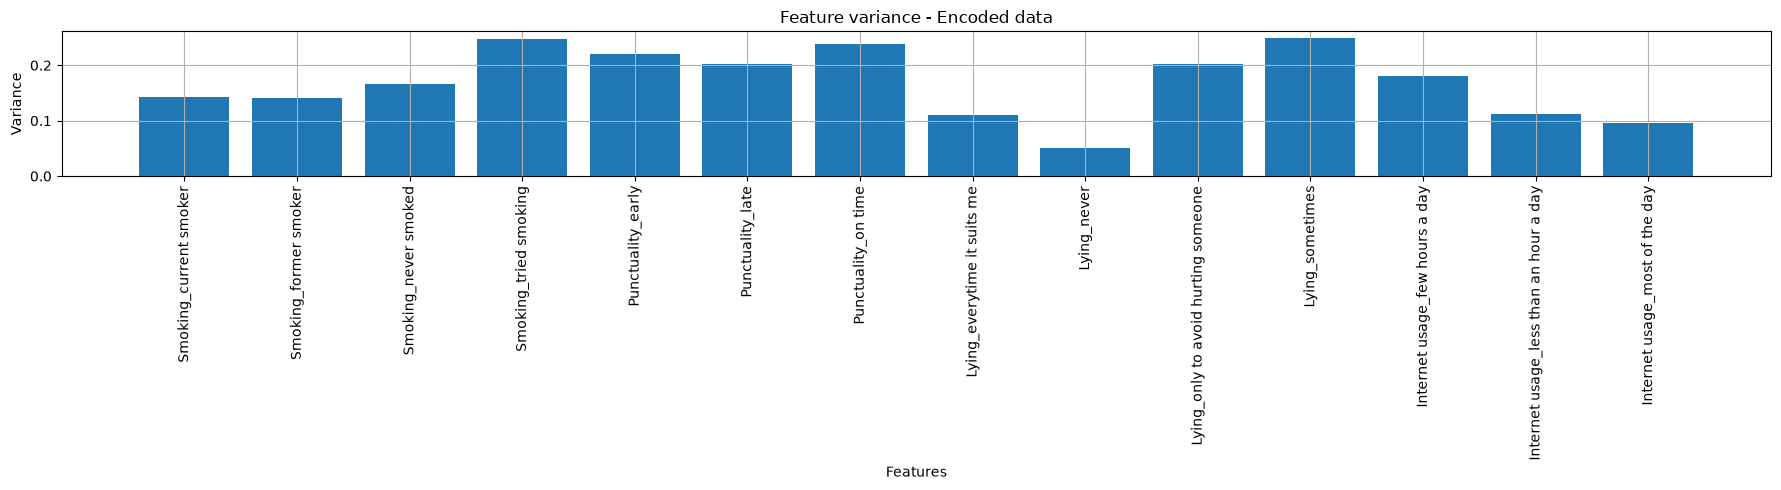

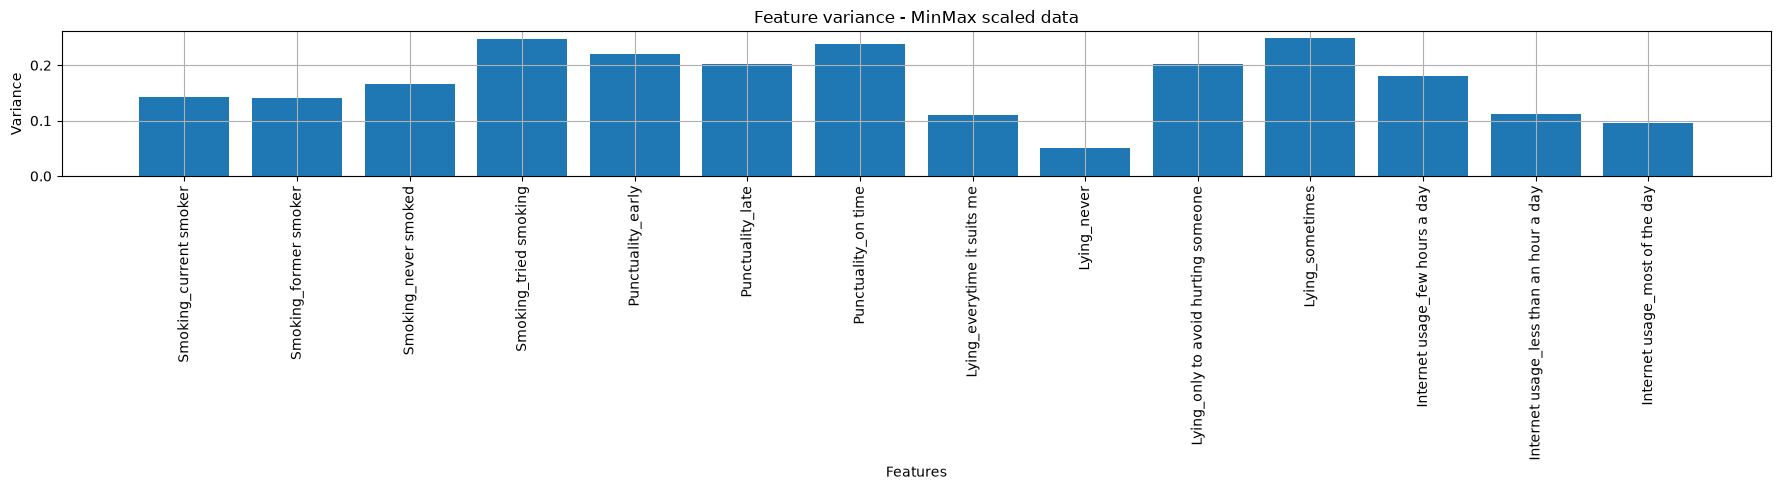

In [12]:

# Compute the variance of each feature
var_enc = responses_ft_enc.var()
var_pp = responses_ft_pp.var()

# Variance of encoded data
plt.figure(figsize=(18, 5))
plt.bar(np.arange(len(var_enc)), var_enc)

plt.xticks(
    ticks=np.arange(len(var_enc)),
    labels=var_enc.index,
    rotation=90
)
plt.title('Feature variance - Encoded data')
plt.xlabel('Features')
plt.ylabel('Variance')
plt.grid()
plt.tight_layout()
plt.show()

# Variance of preprocessed data
plt.figure(figsize=(18, 5))
plt.bar(np.arange(len(var_pp)), var_pp)

plt.xticks(
    ticks=np.arange(len(var_pp)),
    labels=var_pp.index,
    rotation=90
)
plt.title('Feature variance - MinMax scaled data')
plt.xlabel('Features')
plt.ylabel('Variance')
plt.grid()
plt.tight_layout()
plt.show()


#### Comment the results obtained for the variances (max 150 words):
...

#### Write the code for computing all the $n$ PCs of the two datasets, separately, and for visualizing the curves of cumulative explained variances:

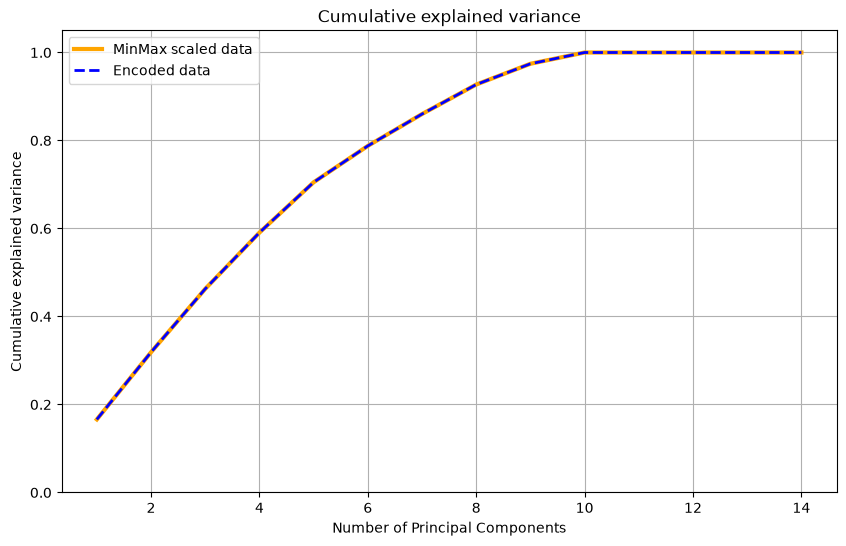

In [14]:

# Initialize PCA objects
pca_enc = PCA()
pca_pp = PCA()

# Fit PCA on both datasets
pca_enc.fit(responses_ft_enc)
pca_pp.fit(responses_ft_pp)

# Compute cumulative explained variance
cumvar_enc = np.cumsum(pca_enc.explained_variance_ratio_)
cumvar_pp = np.cumsum(pca_pp.explained_variance_ratio_)

# Plot cumulative explained variance curves
plt.figure(figsize=(10, 6))

plt.plot(np.arange(1, len(cumvar_pp) + 1),
         cumvar_pp, label='MinMax scaled data',
         color='orange', linewidth=3)

plt.plot(np.arange(1, len(cumvar_enc) + 1),
         cumvar_enc, label='Encoded data',
         color='blue', linestyle='--',
         linewidth=2)

plt.title('Cumulative explained variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative explained variance')
plt.ylim([0, 1.05])
plt.legend()
plt.grid()
plt.show()


#### Comment the results obtained for the cumulative explained variances, knowing the vaues in the datasets and the fetures' variances (max 150 words):

...

## Exercise 3. Dimensionality Reduction and PC Interpretation

In this exercise, you have to do the following operations:
1. For the dataset *responses_ft_pp*, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
1. Visualize as a barplot the explained variance (as percentage) for each PC, and report the preserved explained variance (as percentage) by the $m$ PCs.
1. Visualize all the PCs as barplots and give an interpretation and a name to them, **motivating your choices**.
1. Transform the *responses_ft_pp* data into their $m$-dimensional representation via PCA. Store the transformed data in the variable *responses_ft_pca*;
1. Visualize the the score graph. If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs (given at the previous step) on the axes** for better understanding the results.

#### Write the code for computing the new PCA, for visualizing the $m$ PCs as barplots:

Number of selected PCs: 3


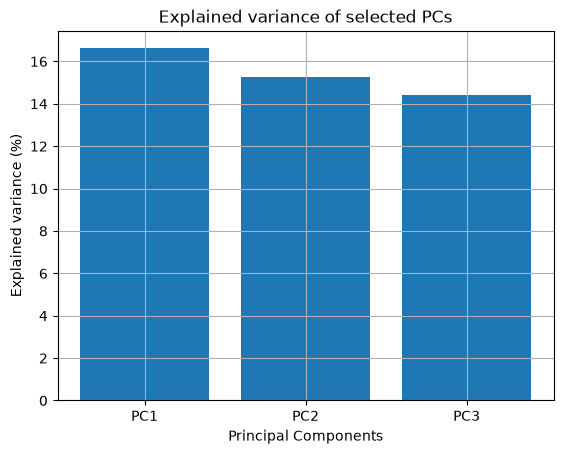

Preserved variance: 46.28%


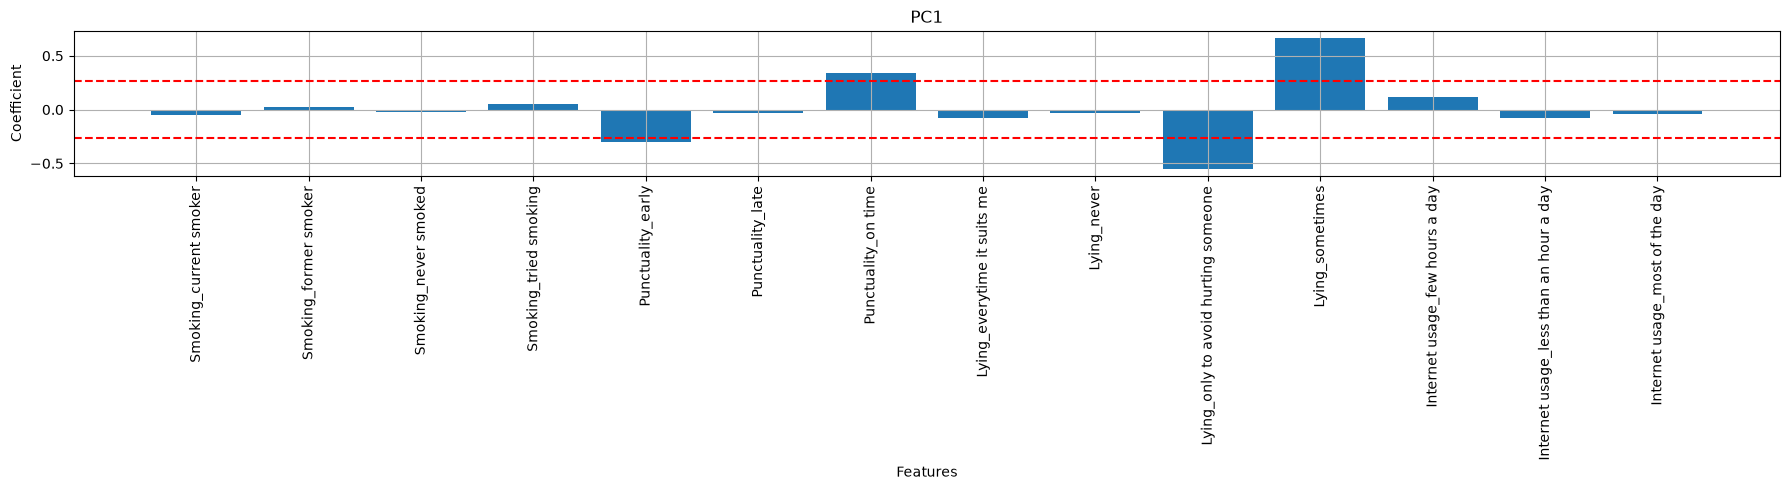

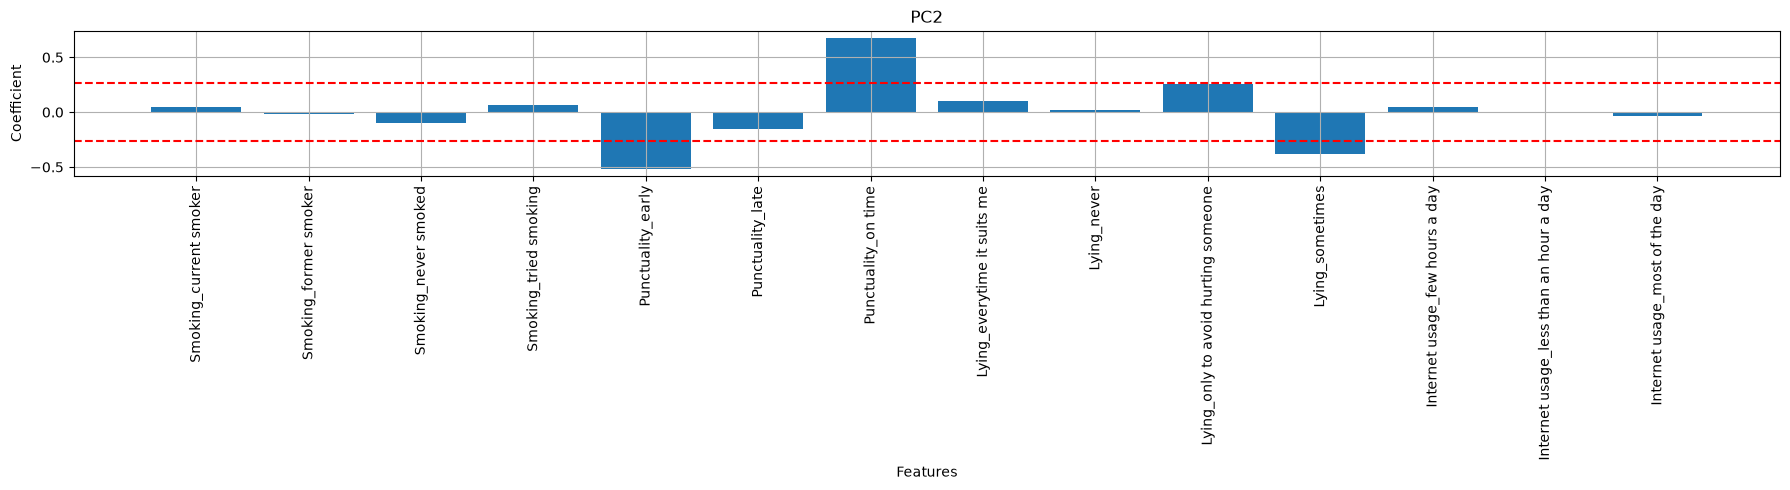

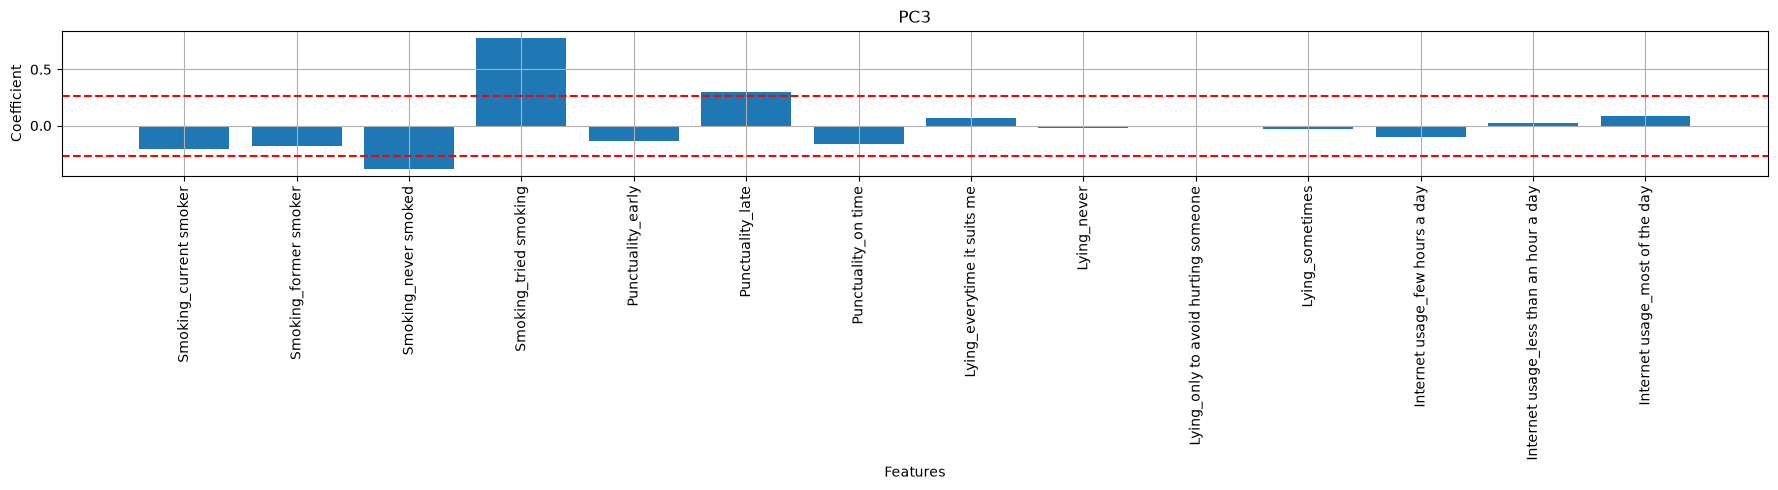

In [15]:

# Compute the number of PCs required to preserve 33% of variance
pca_full = PCA()
pca_full.fit(responses_ft_pp)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)

m_prime = np.argmax(cumvar >= 0.33) + 1
m = min(m_prime, 5)

print(f"Number of selected PCs: {m}")

# Compute the new PCA with m components
pca_m = PCA(n_components=m)
pca_m.fit(responses_ft_pp)

# Plot the explained variance of each PC
plt.figure()
plt.bar(np.arange(1, m + 1),
        pca_m.explained_variance_ratio_ * 100)

plt.xticks(ticks=np.arange(1, m + 1),
           labels=[f'PC{i}' for i in range(1, m + 1)])

plt.xlabel('Principal Components')
plt.ylabel('Explained variance (%)')
plt.title('Explained variance of selected PCs')
plt.grid()
plt.show()

# Print the preserved explained variance
print(f"Preserved variance: {sum(pca_m.explained_variance_ratio_) * 100:.2f}%")

# Plot the coefficients (loadings) of each PC
eps = np.sqrt(1 / pca_m.n_features_in_)

for i in range(m):
    plt.figure(figsize=(18, 5))
    plt.bar(np.arange(pca_m.n_features_in_),
            pca_m.components_[i, :])

    # Threshold for relevant coefficients
    plt.axhline(eps, color='red', linestyle='--')
    plt.axhline(-eps, color='red', linestyle='--')

    plt.xticks(ticks=np.arange(pca_m.n_features_in_),
               labels=responses_ft_pp.columns,
               rotation=90)

    plt.title(f'PC{i+1}')
    plt.xlabel('Features')
    plt.ylabel('Coefficient')
    plt.grid()
    plt.tight_layout()
    plt.show()

# Transform the dataset into the m-dimensional space
responses_ft_pca = pca_m.transform(responses_ft_pp)


#### For each PC, write the name you assigned to it and a brief interpretation that motivate the choice (max 100 words per PC):

...

#### Write the code for visualizing the score graph (with PC names on the axis):

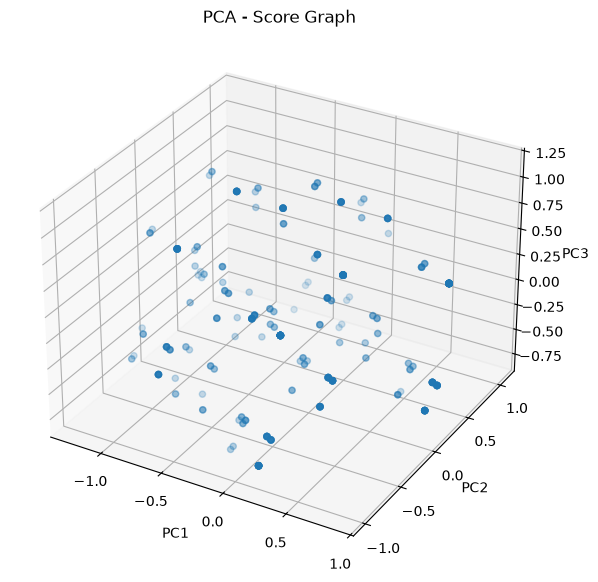

In [16]:

# Names assigned to the Principal Components
pc_names = ['PC1', 'PC2', 'PC3']  # Replace with your chosen names

# Plot the score graph
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    responses_ft_pca[:, 0],
    responses_ft_pca[:, 1],
    responses_ft_pca[:, 2],
    alpha=0.6
)

ax.set_title('PCA - Score Graph')
ax.set_xlabel(pc_names[0])
ax.set_ylabel(pc_names[1])
ax.set_zlabel(pc_names[2])

plt.grid()
plt.show()


## Exercise 4. $k$-Means

In this exercise, you have to do the following operations:
1. Run the $k$-Means for clustering the data of *responses_ft_pca*, **setting the input argument *random_state* equal to the variable *random_seed*** (i.e., the minimum of the Student IDs).

   In particular, **use the silohuette score for identifying the best value for $k\in\{3, \ldots, 10\}$** and show it by plotting how the score changes w.r.t. $k$.
1. Plot the score graph again, but add the centroids of the cluster and color the points according to their cluster.
1. Visualize the centroids coordinates as barplots and **give a name and an interpretation to them by exploiting the PC names**.


#### Write the code for performing the items of the list above:

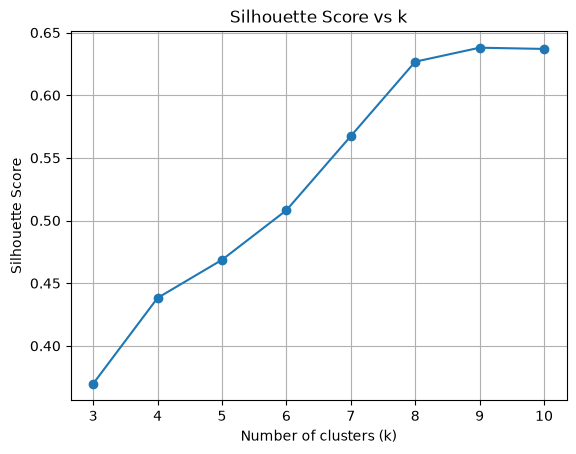

Best k: 9
Silhouette Score: 0.6380


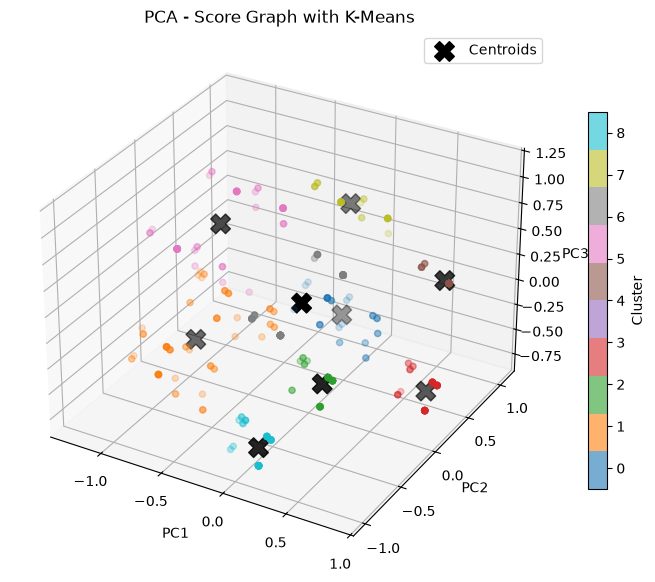

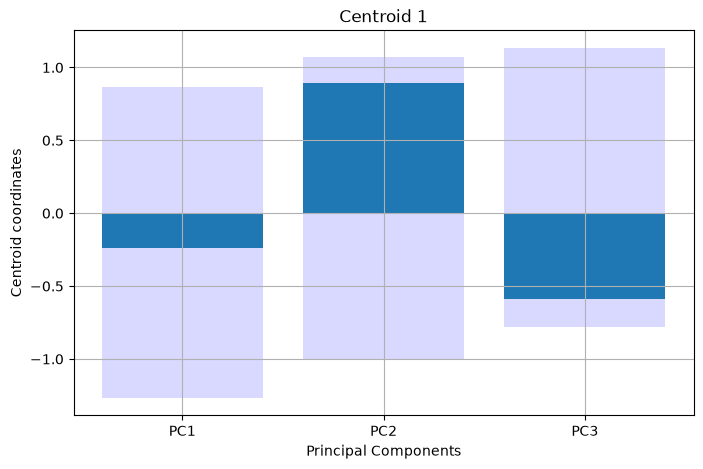

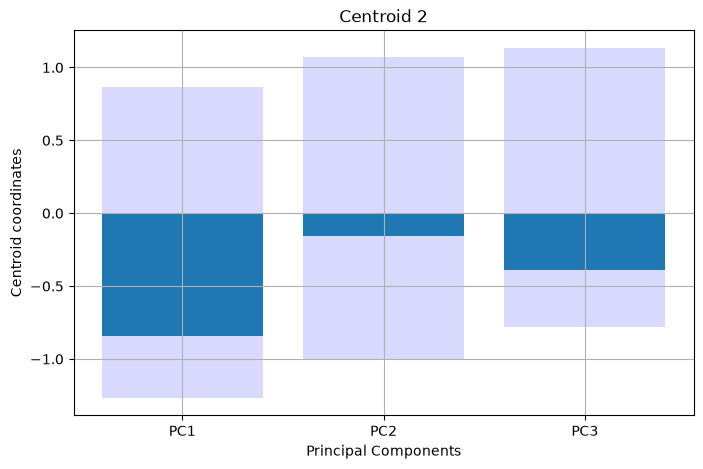

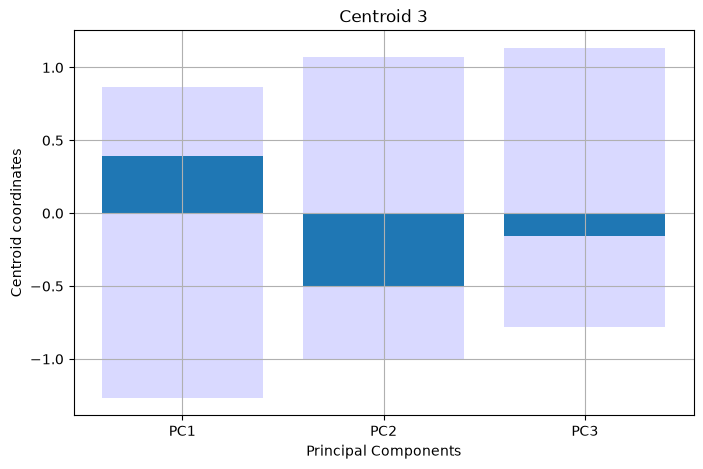

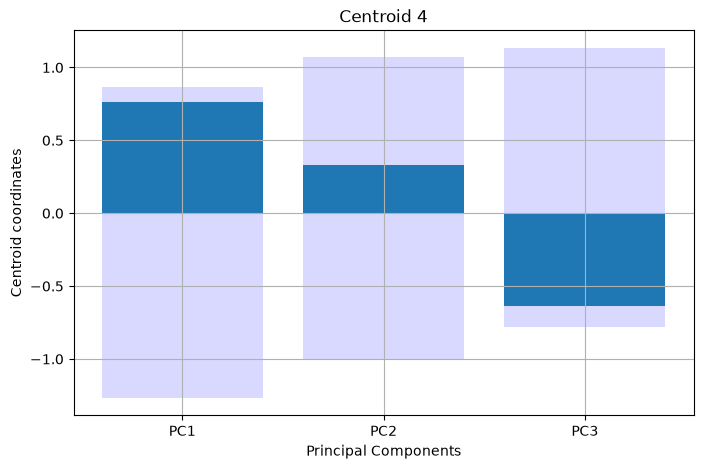

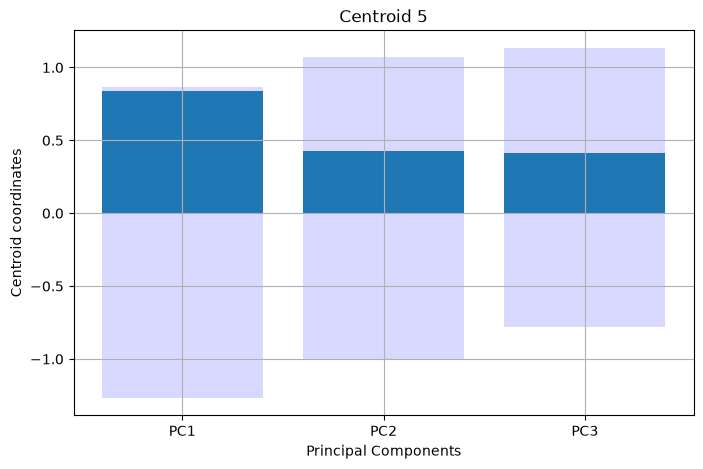

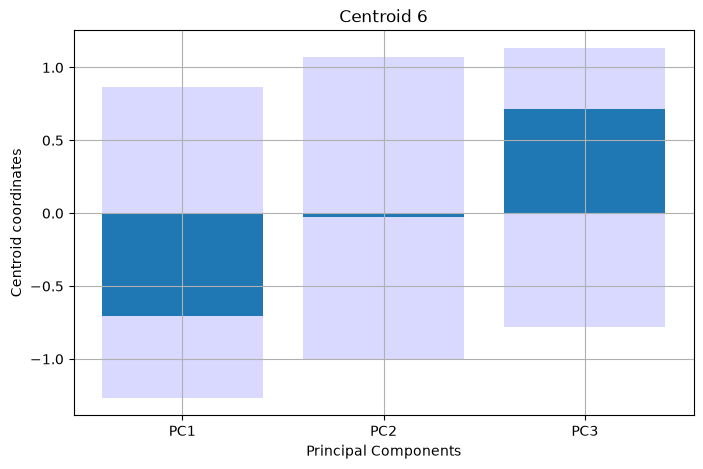

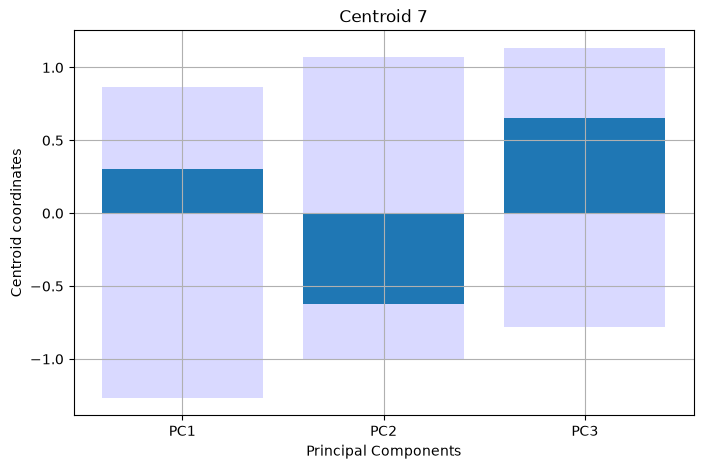

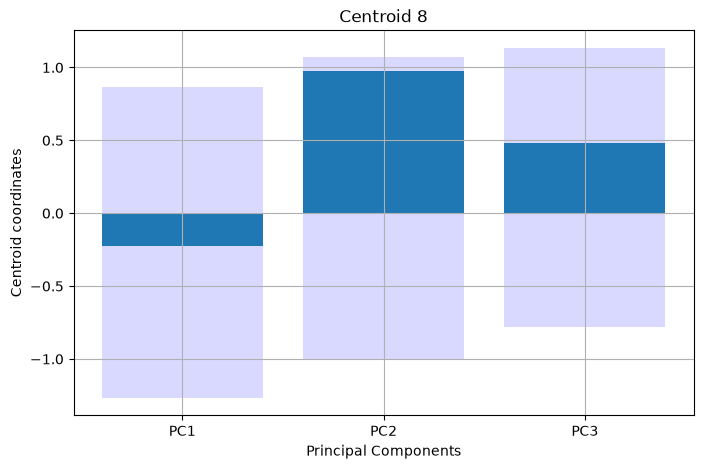

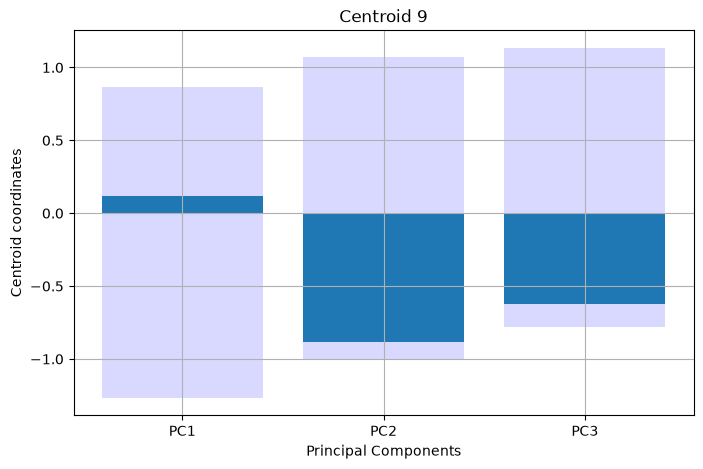

In [19]:
# 1. Find the best k using the silhouette score
k_values = np.arange(3, 11)
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=random_seed, n_init=10)
    km.fit(responses_ft_pca)

    score = silhouette_score(responses_ft_pca, km.labels_)
    silhouette_scores.append(score)

# Plot silhouette scores
plt.figure()
plt.plot(k_values, silhouette_scores, marker='o')
plt.xticks(k_values)
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs k')
plt.grid()
plt.show()

# Select the best k
best_k = k_values[np.argmax(silhouette_scores)]
print(f'Best k: {best_k}')

# Fit K-Means with the best k
km_best = KMeans(n_clusters=best_k, random_state=random_seed, n_init=10)
km_best.fit(responses_ft_pca)

print(f'Silhouette Score: {silhouette_score(responses_ft_pca, km_best.labels_):.4f}')


# 2. Score graph with clusters and centroids
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(
    responses_ft_pca[:, 0],
    responses_ft_pca[:, 1],
    responses_ft_pca[:, 2],
    c=km_best.labels_,
    cmap='tab10',
    vmin=-0.5,
    vmax=best_k-0.5,
    alpha=0.6
)

# Plot centroids
ax.scatter(
    km_best.cluster_centers_[:, 0],
    km_best.cluster_centers_[:, 1],
    km_best.cluster_centers_[:, 2],
    c='black',
    marker='X',
    s=200,
    label='Centroids'
)

ax.set_title('PCA - Score Graph with K-Means')
ax.set_xlabel(pc_names[0])
ax.set_ylabel(pc_names[1])
ax.set_zlabel(pc_names[2])

fig.colorbar(sc, ax=ax, ticks=np.arange(best_k),
             label='Cluster', shrink=0.7)
ax.legend()
plt.show()


# 3. Plot centroid coordinates as barplots
maxs = responses_ft_pca.max(axis=0)
mins = responses_ft_pca.min(axis=0)

for i in range(best_k):
    plt.figure(figsize=(8, 5))

    # Show the range of each PC
    plt.bar(np.arange(m), maxs, color='blue', alpha=0.15)
    plt.bar(np.arange(m), mins, color='blue', alpha=0.15)

    # Centroid coordinates
    plt.bar(np.arange(m), km_best.cluster_centers_[i, :])

    plt.xticks(np.arange(m), pc_names, rotation=0)
    plt.xlabel('Principal Components')
    plt.ylabel('Centroid coordinates')
    plt.title(f'Centroid {i+1}')
    plt.grid()
    plt.show()


#### For each Centroid, write the name you assigned to it and a brief interpretation that motivate the choice by exploiting the PC names(max 100 words per centroid):

...

## Exercise 5. Cluster External Evaluations

In this exercise, you have to do the following operations:
1. Select a subset meaningful labels for performing an external evaluation of the clustering results.
1. For each selected label, visualize the distribution of the label in each cluster and in the whole dataset.
1. Visualize the score graph with dots colored with respect to the label value; then, visualize the clusters in separated score-graphs, coloring the points according to the label values.


#### List the Labels you consider meaningful for an external cluster evaluation and motivate your choice (max 50 words per label):

...


#### Write the code for the visualizations cited in item 2 above:

Distribution of Gender:


,All,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8
female,0.602767,0.530612,0.56962,0.731707,0.590164,0.55102,0.546875,0.64,0.7,0.625
male,0.397233,0.469388,0.43038,0.268293,0.409836,0.44898,0.453125,0.36,0.3,0.375


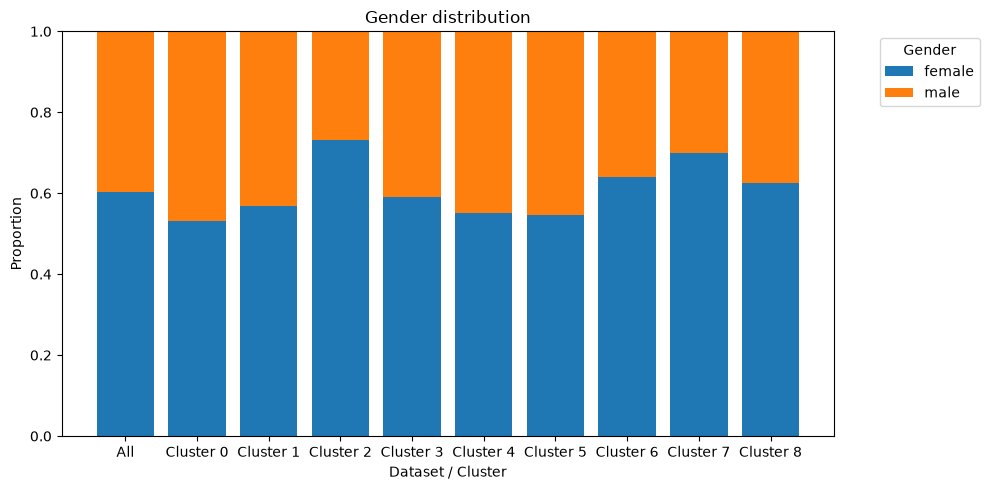

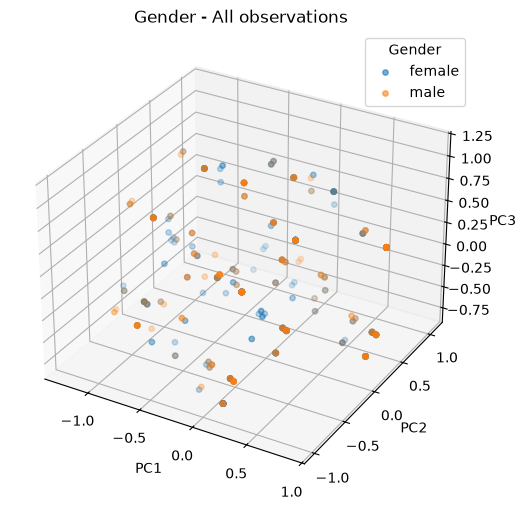

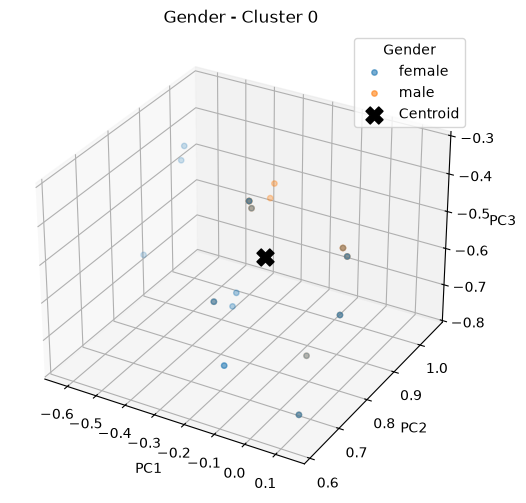

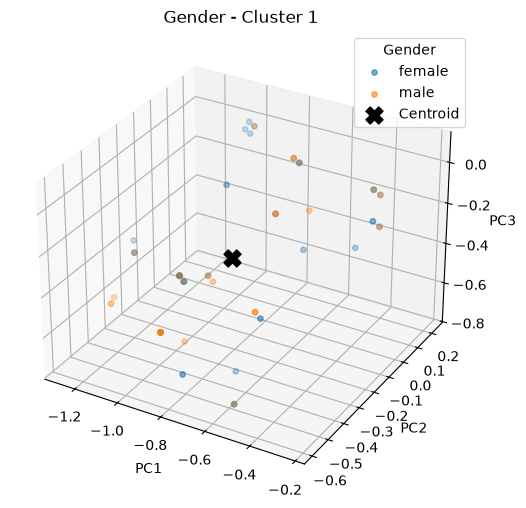

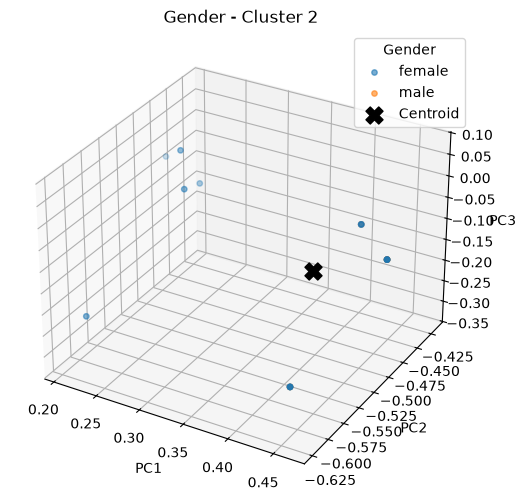

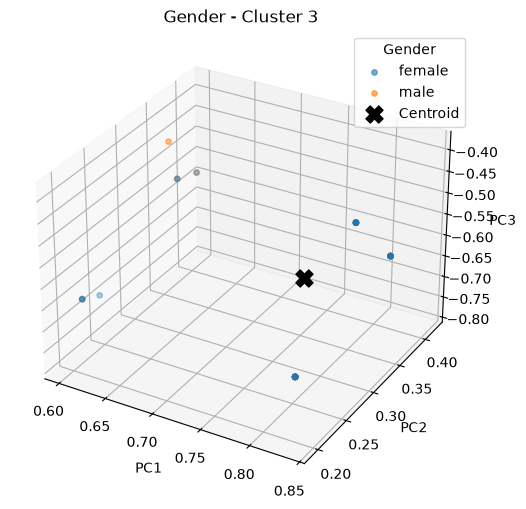

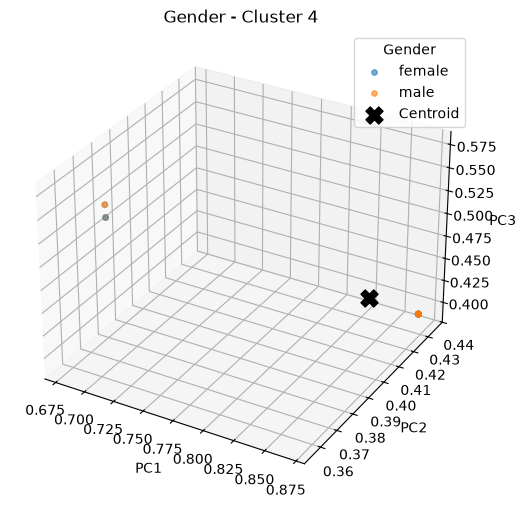

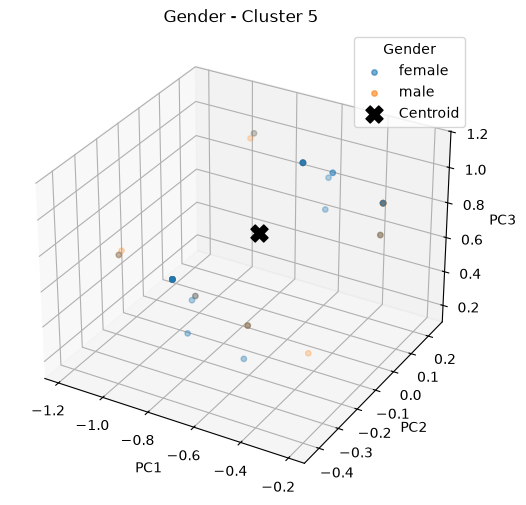

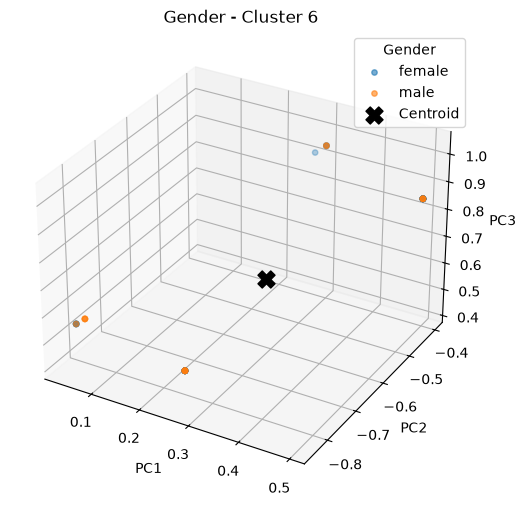

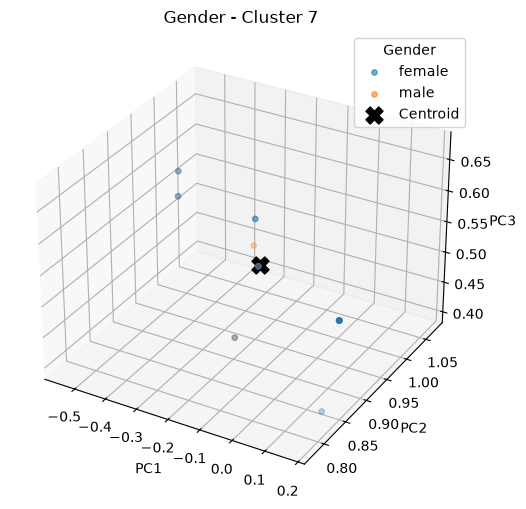

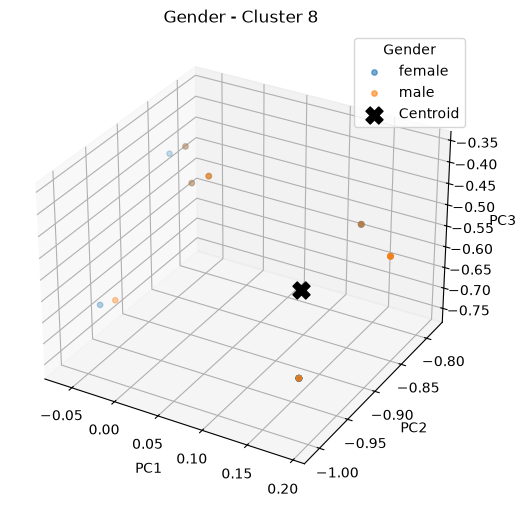

Distribution of Education:


,All,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8
college/bachelor degree,0.197628,0.22449,0.189873,0.146341,0.229508,0.142857,0.1875,0.28,0.15,0.166667
currently a primary school pupil,0.003953,0.0,0.0,0.0,0.016393,0.0,0.0,0.013333,0.0,0.0
doctorate degree,0.003953,0.020408,0.0,0.0,0.0,0.0,0.015625,0.0,0.0,0.0
masters degree,0.073123,0.040816,0.126582,0.02439,0.114754,0.081633,0.046875,0.066667,0.025,0.083333
primary school,0.077075,0.122449,0.075949,0.073171,0.081967,0.040816,0.0625,0.04,0.1,0.125
secondary school,0.644269,0.591837,0.607595,0.756098,0.557377,0.734694,0.6875,0.6,0.725,0.625


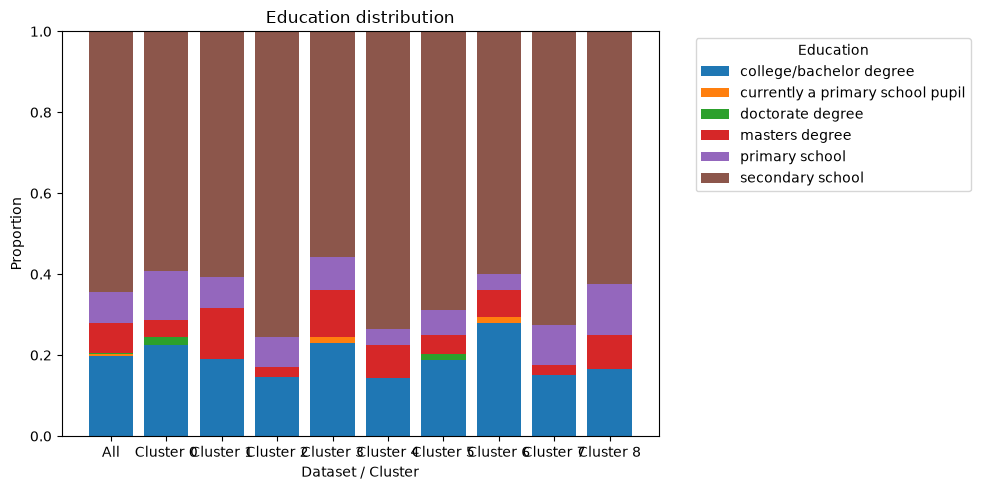

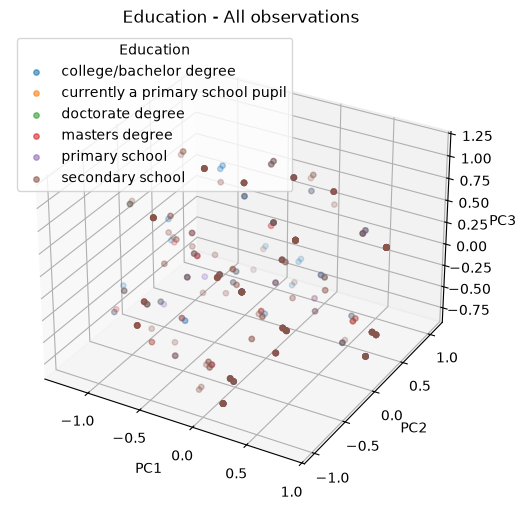

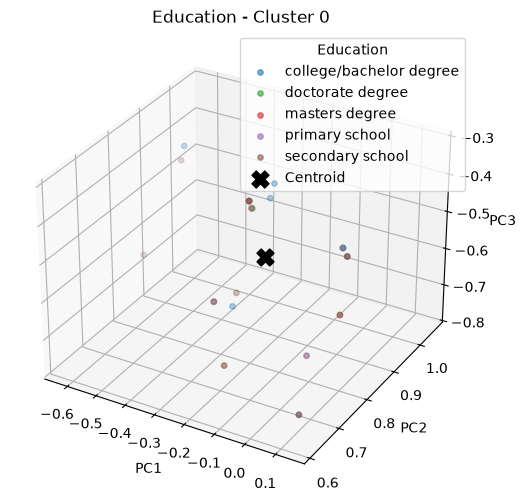

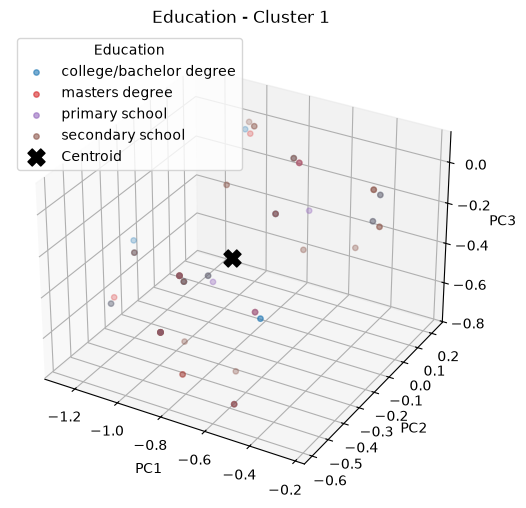

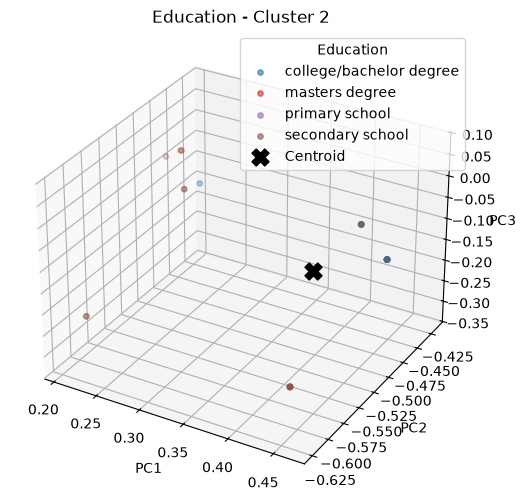

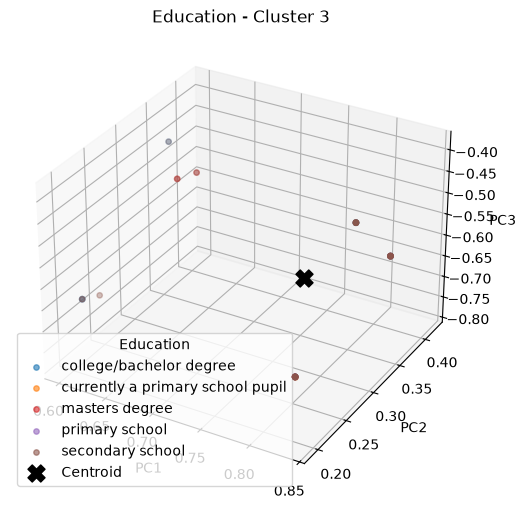

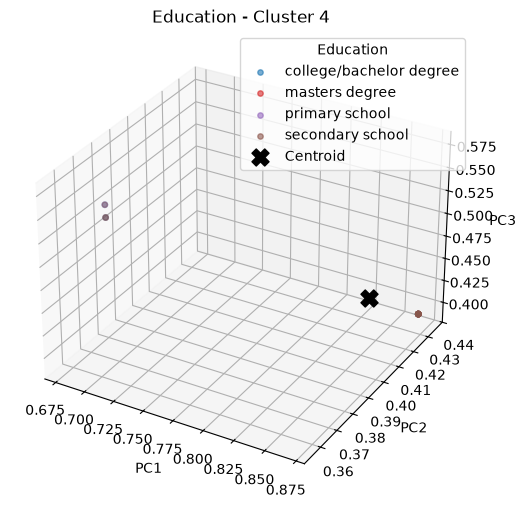

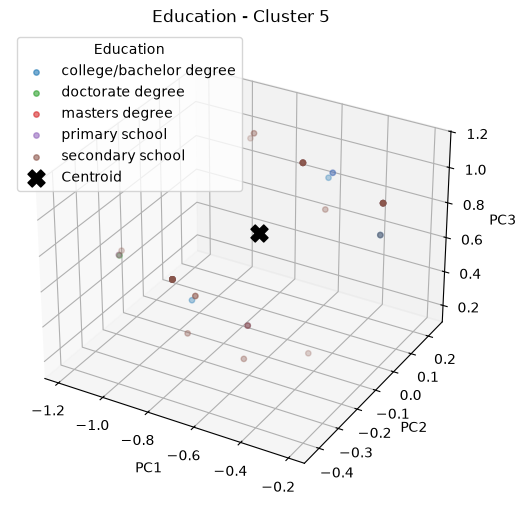

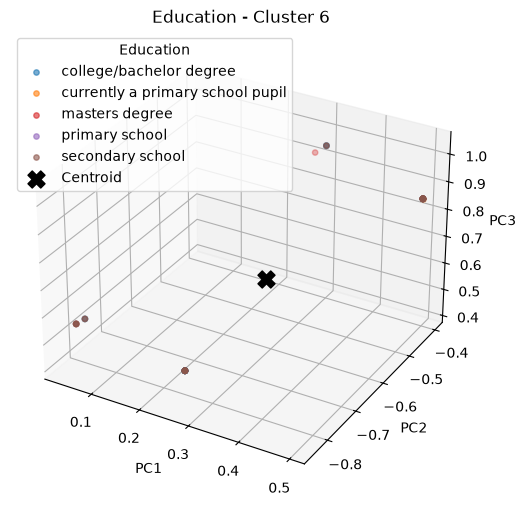

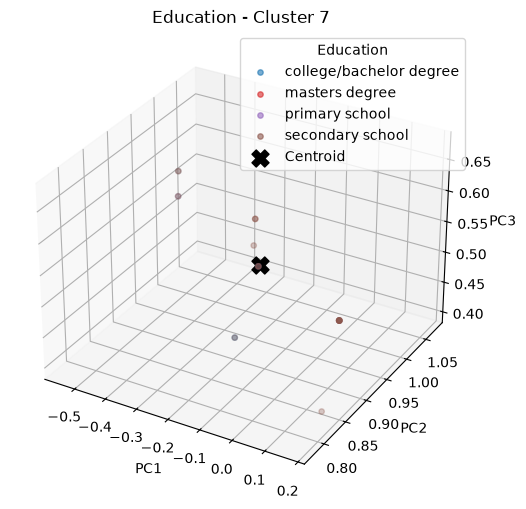

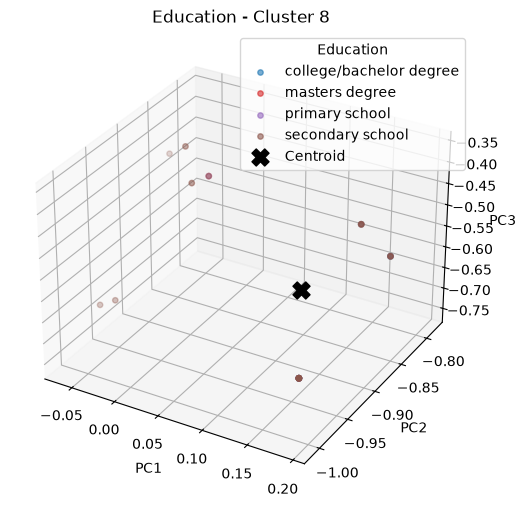

Distribution of Home Town Type:


,All,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7,Cluster 8
city,0.715415,0.755102,0.670886,0.780488,0.786885,0.653061,0.703125,0.733333,0.675,0.6875
village,0.284585,0.244898,0.329114,0.219512,0.213115,0.346939,0.296875,0.266667,0.325,0.3125


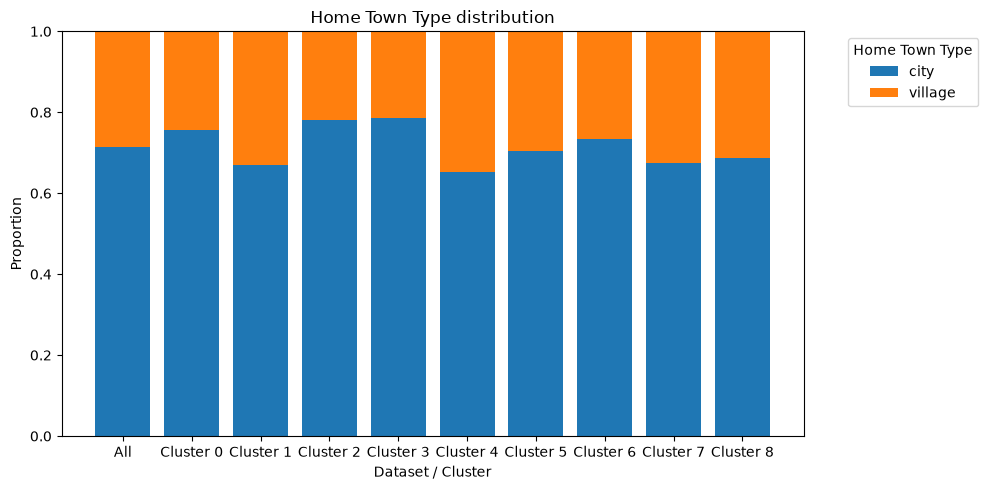

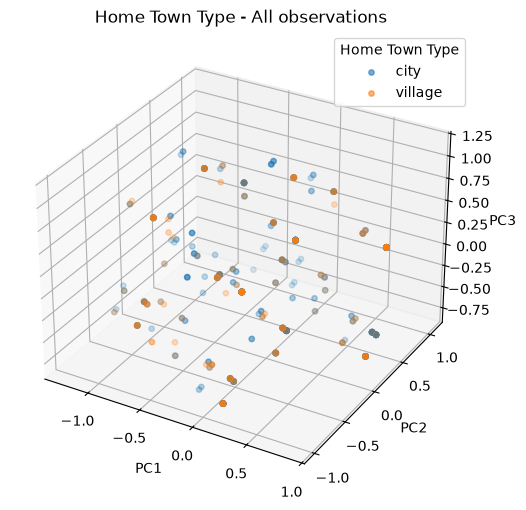

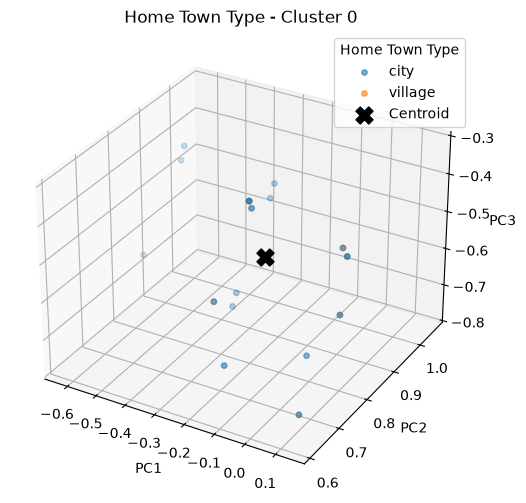

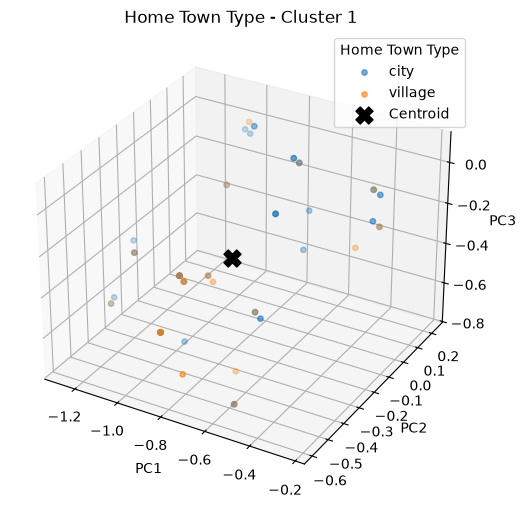

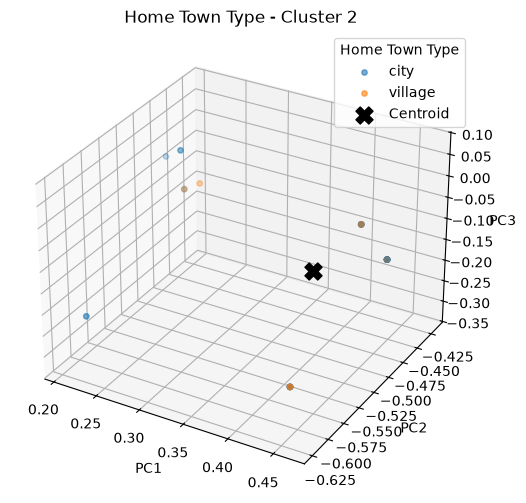

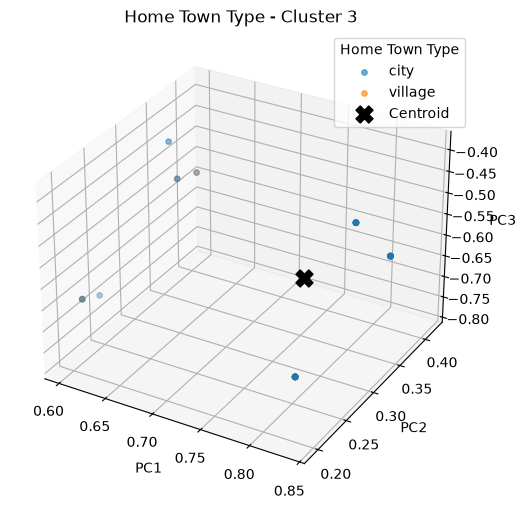

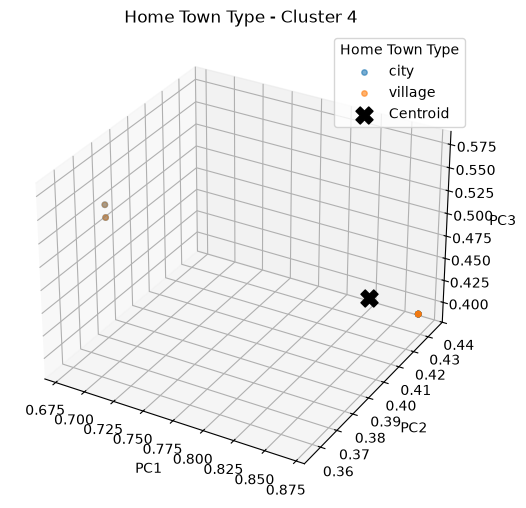

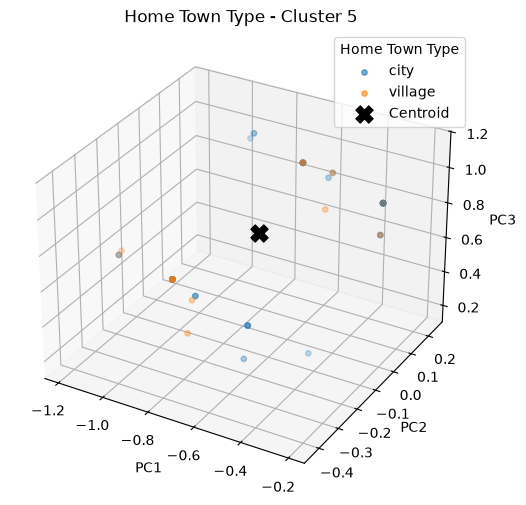

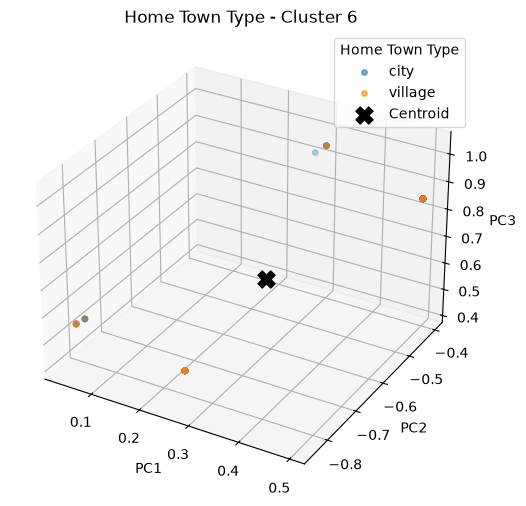

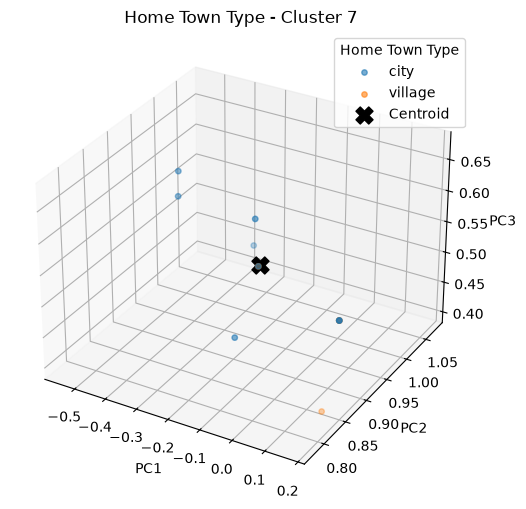

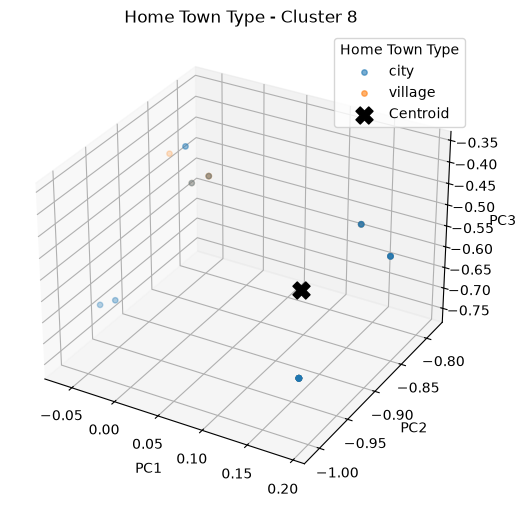

In [21]:

# Selected labels
selected_labels = ['Gender', 'Education', 'Home Town Type']

# Check that rows have the same order
assert responses_lb.index.equals(responses_ft_pp.index)
assert len(responses_lb) == len(km_best.labels_)

for label in selected_labels:

    values = responses_lb[label].astype('string').fillna('Missing')
    categories = sorted(values.unique())

    # Assign a color to each label value
    colors = plt.get_cmap('tab10').colors
    category_colors = {
        cat: colors[i % len(colors)]
        for i, cat in enumerate(categories)
    }

    # 1. Compute label distributions
    distributions = pd.DataFrame(index=categories)

    distributions['All'] = values.value_counts(normalize=True)

    for i in range(best_k):
        distributions[f'Cluster {i}'] = (
            values.iloc[km_best.labels_ == i]
            .value_counts(normalize=True)
        )

    distributions = distributions.fillna(0)

    print(f'Distribution of {label}:')
    display(distributions)

    # 2. Plot distributions
    plt.figure(figsize=(10, 5))

    x = np.arange(best_k + 1)
    bottom = np.zeros(best_k + 1)

    for cat in categories:
        heights = distributions.loc[cat].to_numpy(dtype=float)

        plt.bar(x, heights, bottom=bottom,
                color=category_colors[cat], label=cat)

        bottom += heights

    plt.xticks(x, distributions.columns)
    plt.xlabel('Dataset / Cluster')
    plt.ylabel('Proportion')
    plt.ylim(0, 1)
    plt.title(f'{label} distribution')
    plt.legend(title=label, bbox_to_anchor=(1.05, 1),
               loc='upper left')
    plt.tight_layout()
    plt.show()

    # 3. Score graph of all data and individual clusters
    for cluster in [None] + list(range(best_k)):

        if cluster is None:
            mask = np.ones(len(values), dtype=bool)
            graph_title = 'All observations'
        else:
            mask = km_best.labels_ == cluster
            graph_title = f'Cluster {cluster}'

        fig = plt.figure(figsize=(9, 6))
        ax = fig.add_subplot(111, projection='3d')

        for cat in categories:
            selected = mask & (values.to_numpy() == cat)

            if np.any(selected):
                ax.scatter(
                    responses_ft_pca[selected, 0],
                    responses_ft_pca[selected, 1],
                    responses_ft_pca[selected, 2],
                    color=category_colors[cat],
                    label=cat,
                    alpha=0.6,
                    s=15
                )

        # Add centroid in individual cluster graphs
        if cluster is not None:
            centroid = km_best.cluster_centers_[cluster]

            ax.scatter(
                centroid[0],
                centroid[1],
                centroid[2],
                c='black',
                marker='X',
                s=150,
                label='Centroid'
            )

        ax.set_title(f'{label} - {graph_title}')
        ax.set_xlabel(pc_names[0])
        ax.set_ylabel(pc_names[1])
        ax.set_zlabel(pc_names[2])
        ax.legend(title=label)

        plt.show()


#### For each selected label, comment the results observed in the visualizations (max 100 words per label):

...

## Exercise 6. Cluster Internal Evaluations

In this exercise, you have to do the following operations:
1. For each cluster, measure the corresponding average silhouette score
1. Visualize the silhouette of the clusters and the general one of the clustering and compare them


#### Write the code for computing the silhouette scores and for visualizing them:

Cluster 0: 0.6191
Cluster 1: 0.4509
Cluster 2: 0.7250
Cluster 3: 0.8154
Cluster 4: 0.9361
Cluster 5: 0.4531
Cluster 6: 0.5568
Cluster 7: 0.6648
Cluster 8: 0.7117
Overall silhouette score: 0.6380


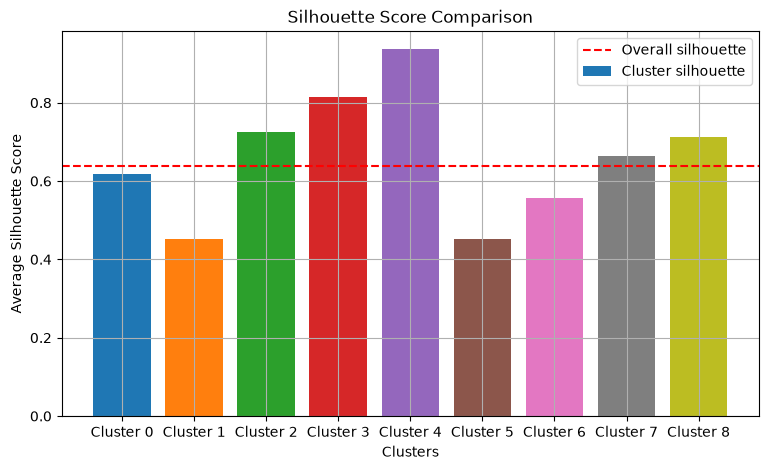

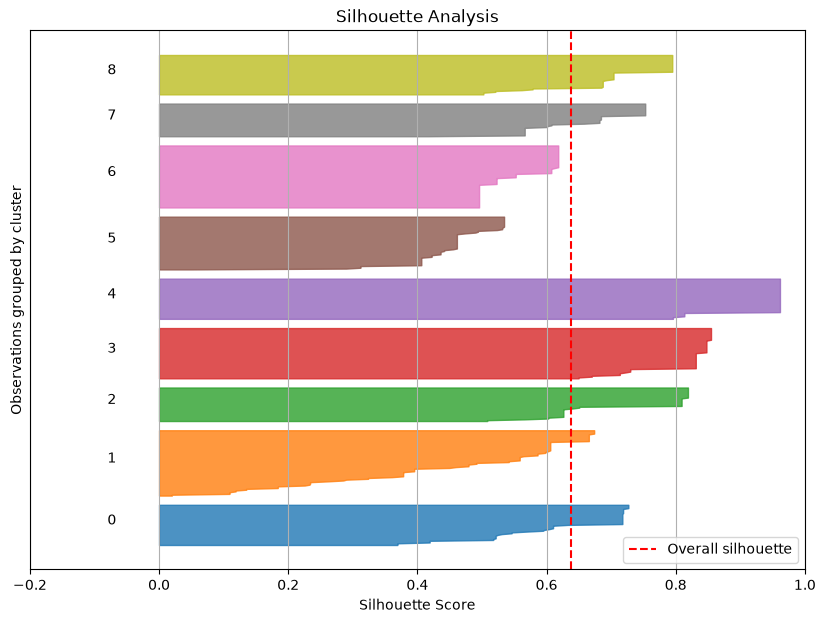

In [23]:
# Compute silhouette scores for each observation
sample_scores = silhouette_samples(
    responses_ft_pca, km_best.labels_
)

# Compute overall silhouette score
overall_score = silhouette_score(
    responses_ft_pca, km_best.labels_
)

# Compute average silhouette score for each cluster
cluster_scores = []

for i in range(best_k):
    score = np.mean(sample_scores[km_best.labels_ == i])
    cluster_scores.append(score)

    print(f'Cluster {i}: {score:.4f}')

print(f'Overall silhouette score: {overall_score:.4f}')


# 1. Plot average silhouette scores
colors = plt.get_cmap('tab10').colors

plt.figure(figsize=(9, 5))

plt.bar(
    np.arange(best_k),
    cluster_scores,
    color=colors[:best_k],
    label='Cluster silhouette'
)

plt.axhline(
    overall_score,
    color='red',
    linestyle='--',
    label='Overall silhouette'
)

plt.xticks(np.arange(best_k),
           [f'Cluster {i}' for i in range(best_k)])

plt.xlabel('Clusters')
plt.ylabel('Average Silhouette Score')
plt.title('Silhouette Score Comparison')
plt.legend()
plt.grid()
plt.show()


# 2. Silhouette plot for each cluster
plt.figure(figsize=(10, 7))

y_lower = 10

for i in range(best_k):

    # Select and sort the silhouette scores
    cluster_sample_scores = sample_scores[km_best.labels_ == i]
    cluster_sample_scores.sort()

    cluster_size = len(cluster_sample_scores)
    y_upper = y_lower + cluster_size

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_sample_scores,
        color=colors[i],
        alpha=0.8
    )

    plt.text(-0.08, y_lower + cluster_size / 2, str(i))

    y_lower = y_upper + 10

# Overall silhouette score
plt.axvline(
    overall_score,
    color='red',
    linestyle='--',
    label='Overall silhouette'
)

plt.xlabel('Silhouette Score')
plt.ylabel('Observations grouped by cluster')
plt.title('Silhouette Analysis')
plt.xlim([-0.2, 1])
plt.yticks([])
plt.legend()
plt.grid()
plt.show()


#### Comment the results, also considering the results observed previously (e.g., score graphs, centroids, etc. - max 150 words):

...